In [1]:
# Parameters
wd = "/data/GR_dex"
n_jobs = 8


# DEX/No-DEX Footprinting

#### Files:

- `Glucocorticoid receptor (GR/NR3C1?) BED file`: List of genomic sites where GR binds [chromosome, start, end, name, score, strand]
    - Generated from JASPAR NR3C1 MA0113.1 MEME file using FIMO
- `Tn5 Bias File for Mice`: genome=scp.genome.mm10; already including in scPrinter
- `Fragment file`: 2 BAM files for dex/no-dex, converted to fragment tsv

In [2]:
import os
import platform
import numpy as np
import sys
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
ON_MAC = platform.system() == "Darwin"
if ON_MAC:
    os.environ.pop("SCPRINTER_DATA", None)   #Mac: use the default cache
import scprinter as scp
import scprinter.tools as _sct
from concurrent.futures import Future
import h5py

#Mac-only workaround: scPrinter's parallel workers fail on macOS, so run jobs one at a time.
class _SerialExecutor:
    def __init__(self, *args, **kwargs): pass
    def submit(self, fn, *args, **kwargs):
        f = Future()
        try:
            f.set_result(fn(*args, **kwargs))
        except Exception as e:
            f.set_exception(e)
        return f
    def shutdown(self, *args, **kwargs): pass
    def __enter__(self): return self
    def __exit__(self, *exc): self.shutdown()

if ON_MAC:
    _sct.ProcessPoolExecutor = _SerialExecutor

    #Mac-only memory fix: read Tn5 bias from the bigWig instead of loading the whole-genome .h5 (~11 GB)
    from scprinter.io import get_bias_insertions as _orig_get_bias
    def _get_bias_from_bw(printer, regions, bias_mode="h5", **kwargs):
        return _orig_get_bias(printer, regions, bias_mode="bw", **kwargs)
    _sct.get_bias_insertions = _get_bias_from_bw

import time
import pandas as pd
import pybedtools
import matplotlib.pyplot as plt
import re
import math
import copy
import pyBigWig
from tqdm import tqdm
from zipfile import ZipFile
import seaborn as sns
import scipy.stats as ss
import torch

/tmp/scprinter_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Where the data lives: NRP's job sets GR_WD and N_JOBS; on the Mac these fall back to the defaults
wd = os.environ.get("GR_WD", os.path.expanduser("~/Documents/GitHub/printing/data"))
n_jobs = int(os.environ.get("N_JOBS", "1"))
print("wd:", wd, "| n_jobs:", n_jobs)

wd: /data/GR_dex | n_jobs: 8


In [4]:
os.makedirs(os.path.join(wd, "plots"), exist_ok=True)
print("wd:", wd, "| n_jobs:", n_jobs)

wd: /data/GR_dex | n_jobs: 8


In [5]:
barcodes = ['no_dex', 'dex']

### Load GR BED File

| Col | Content |
| --- | --- |
| 0 | chromosome |
| 1 | motif start (0-based, inclusive) |
| 2 | motif end (0-based, exclusive) |
| 3 | name + seq |
| 4 | p-value: smaller = stronger match to GR motif |
| 5 | negative/positive strand |

In [6]:
gr_bed = pd.read_table(os.path.join(wd, 'GR_motifs_mm10.bed'), header=None)
print('sites (filtered to p-val < 0.0001):', gr_bed.shape[0])
gr_bed.head(10)

sites (filtered to p-val < 0.0001): 519243


,0,1,2,3,4,5
0,chr1,3002020,3002038,GR_GAGAAGAAAACTTCCCAA,0.000015,-
1,chr1,3003351,3003369,GR_GAGAACAGTCTGTGCAGA,0.000070,-
2,chr1,3012791,3012809,GR_AAAAACAGTCAGTTGTGC,0.000061,+
3,chr1,3014633,3014651,GR_AAAACCAGCCTGACCAGG,0.000087,+
4,chr1,3021987,3022005,GR_AGAAGCATACAGAACTGT,0.000072,+
5,chr1,3023377,3023395,GR_GGAAACAAAAAGAACTAT,0.000033,+
6,chr1,3026770,3026788,GR_AGGAAAAAAATTTCCAAT,0.000074,-
7,chr1,3034095,3034113,GR_AAAAACATCATGTTCTAC,0.000001,-
8,chr1,3034271,3034289,GR_AGAAACAAAAAGAACTAT,0.000055,-
9,chr1,3036023,3036041,GR_AAGAAGATTATTTTCTTG,0.000029,+


### Download mm10 Files

In [7]:
scp.genome.mm10.fetch_bias()       # mouse Tn5 bias (.h5)
bw = scp.genome.mm10.fetch_bias_bw()
b = pyBigWig.open(bw); print(b.values("chr1", 3002020, 3002030)); b.close() 

  0%|                                              | 0.00/10.9G [00:00<?, ?B/s]

  0%|                                 | 1.02k/10.9G [00:00<387:21:13, 7.83kB/s]

  0%|                                   | 32.8k/10.9G [00:00<18:57:19, 160kB/s]

  0%|                                   | 81.9k/10.9G [00:00<10:41:29, 284kB/s]

  0%|                                     | 131k/10.9G [00:00<8:48:00, 345kB/s]

  0%|                                     | 279k/10.9G [00:00<4:22:37, 693kB/s]

... (20,260 outputs left out)

 94%|█████████▍| 62/66 [21:37<00:41, 10.38s/it]

 97%|█████████▋| 64/66 [21:37<00:16,  8.47s/it]

100%|██████████| 66/66 [21:37<00:00, 19.66s/it]

bias bigwig created
[0.0876321941614151, 0.43210163712501526, 0.2552497982978821, 0.25499406456947327, 0.038610637187957764, 0.03572392463684082, 0.3674987554550171, 0.06727196276187897, 0.277785986661911, 0.0833393782377243]


In [8]:
# Loads GR_printer.h5ad if fragments were already imported; otherwise imports them
h5ad_path = os.path.join(wd, 'GR_printer.h5ad')
done_flag = os.path.join(wd, 'GR_printer.DONE') 

if os.path.exists(done_flag):
    print("Loading existing printer object...")
    printer = scp.load_printer(h5ad_path, scp.genome.mm10)
else:
    print("Importing fragments (first run, this takes a while)...")
    if os.path.exists(h5ad_path):
        os.remove(h5ad_path)            # clear any half-written file from an interrupted run
    printer = scp.pp.import_fragments(
        path_to_frags=os.path.join(wd, 'GR_all.frags.tsv.gz'),
        barcodes=barcodes,
        savename=h5ad_path,
        genome=scp.genome.mm10,
        sorted_by_barcode=True)
    open(done_flag, 'w').close()        # mark as finished

# Dispersion model: expected center/flank cut ratio on bare DNA, given Tn5 bias and coverage
printer.load_disp_model()

Importing fragments (first run, this takes a while)...
single input


Detecting the shift in the paired end fragments file
If you think the above message is wrong, please check the input file format


  0%|                                               | 0.00/774M [00:00<?, ?B/s]

  0%|                                    | 8.19k/774M [00:00<2:42:22, 79.4kB/s]

  0%|                                       | 48.1k/774M [00:00<51:31, 250kB/s]

  0%|                                       | 96.3k/774M [00:00<38:21, 336kB/s]

... (5,060 outputs left out)

  0%|                                              | 0.00/24.0M [00:00<?, ?B/s]

100%|█████████████████████████████████████| 24.0M/24.0M [00:00<00:00, 38.4GB/s]


Decompressing '/data/scprinter_cache/gencode_vM25_GRCm38.gff3.gz' to '/data/scprinter_cache/gencode_vM25_GRCm38.gff3.gz.decomp' using method 'gzip'.


Creating GFF database (Runs for new genome)


### Choose GR Sites to Footprint
- motif sites that are accessible and open up with dex
- testing out keeping top 3000 sites for now


In [9]:
window = 500          
min_cuts = 200        
min_log2fc = 1        

gr_sites = gr_bed.copy()
gr_sites["center"] = (gr_sites[1] + gr_sites[2]) // 2

ins = printer.fetch_insertion_profile()
bc = list(printer.insertion_file.obs_names)
row_nodex, row_dex = bc.index("no_dex"), bc.index("dex")

cuts_nodex = np.zeros(len(gr_sites)); cuts_dex = np.zeros(len(gr_sites))
total_nodex = total_dex = 0
for chrom in tqdm(gr_sites[0].unique()):
    if chrom not in ins:
        continue
    m = ins[chrom]
    idx = np.where(gr_sites[0].values == chrom)[0]
    c = gr_sites["center"].values[idx]
    for row, out in [(row_nodex, cuts_nodex), (row_dex, cuts_dex)]:
        track = np.asarray(m[row].todense()).ravel()                    # one condition, one chromosome
        cs = np.concatenate([[0], np.cumsum(track, dtype=np.int64)])    # cumulative sum -> fast window sums
        lo = np.clip(c - window, 0, len(track)); hi = np.clip(c + window, 0, len(track))
        out[idx] = cs[hi] - cs[lo]
        if row == row_nodex: total_nodex += cs[-1]
        else:                total_dex   += cs[-1]
        del track, cs
del ins; import gc; gc.collect()

gr_sites["cuts_no_dex"] = cuts_nodex
gr_sites["cuts_dex"]    = cuts_dex
cpm_nodex = cuts_nodex / total_nodex * 1e6               #normalize for sequencing depth
cpm_dex   = cuts_dex   / total_dex   * 1e6
gr_sites["log2FC"] = np.log2((cpm_dex + 0.1) / (cpm_nodex + 0.1))

GR_filt = gr_sites[(gr_sites["cuts_no_dex"] + gr_sites["cuts_dex"] > min_cuts) &
                   (gr_sites["log2FC"] > min_log2fc)].sort_values("log2FC", ascending=False)
print(f"{len(gr_sites):,} motif sites -> {len(GR_filt):,} accessible and dex-responsive")

GR_filt.to_csv(os.path.join(wd, "GR_sites_filtered.tsv"), sep="\t", index=False)   # small, gets downloaded
GR_filt.head()

Loading insertion profiles


  0%|          | 0/21 [00:00<?, ?it/s]

  5%|▍         | 1/21 [00:06<02:04,  6.24s/it]

 10%|▉         | 2/21 [00:11<01:43,  5.46s/it]

 14%|█▍        | 3/21 [00:15<01:25,  4.73s/it]

 19%|█▉        | 4/21 [00:18<01:13,  4.32s/it]

... (16 outputs left out)

100%|██████████| 21/21 [01:31<00:00,  4.12s/it]

100%|██████████| 21/21 [01:31<00:00,  4.36s/it]

519,243 motif sites -> 80 accessible and dex-responsive


,0,1,2,3,4,5,center,cuts_no_dex,cuts_dex,log2FC
231097,chr19,16949117,16949135,GR_CAATGCAGCATGTTCTGA,3.260000e-05,+,16949126,62.0,445.0,2.364476
231096,chr19,16948977,16948995,GR_GAGAACAGTATGTCCCAG,4.260000e-08,-,16948986,63.0,447.0,2.353647
338154,chr5,25414502,25414520,GR_GAGGACAGAATGTCCTAA,3.940000e-07,+,25414511,76.0,506.0,2.319709
338155,chr5,25414795,25414813,GR_AAAATGATAAAGTCCCAC,9.570000e-05,+,25414804,81.0,466.0,2.135162
240852,chr2,7242306,7242324,GR_GGGAAGAGAAAGAACAGG,7.610000e-05,-,7242315,115.0,614.0,2.106083


### Calculate an Aggregate Footprint

In [10]:
n_top = min(len(GR_filt), 3000) 
sites = GR_filt.iloc[:n_top]

agg_regions, agg_strands = [], []
for _, row in sites.iterrows():
    c = int(row["center"])
    agg_regions.append(f"{row[0]}:{c-500}-{c+500}")
    agg_strands.append(row[5])

cond_groups = pd.DataFrame({"barcode": ["no_dex", "dex"], "group": ["no_dex", "dex"]})
grouping2, groups2 = scp.utils.df2cell_grouping(printer, cond_groups)
print(groups2)                                    # ['dex' 'no_dex'] (sorted alphabetically)

t0 = time.time()
scp.tl.get_footprint_score(printer, grouping2, groups2, agg_regions,
    modes=np.arange(2, 101), footprintRadius=None, flankRadius=None,
    n_jobs=n_jobs, save_key="GR_dex_sites", backed=True, overwrite=True)
print(f"takes {(time.time() - t0)/60:.1f} min")

['dex' 'no_dex']
estimated file size: 0.06 GB
Creating GR_dex_sites in printer.footprintsadata
obs=groups, var=regions
8000 100


Submitting jobs:   0%|          | 0/7920 [00:00<?, ?it/s]

collecting multi-scale footprints:   0%|          | 0/7920 [00:00<?, ?it/s]

Submitting jobs:   1%|          | 80/7920 [00:01<01:50, 70.87it/s]

collecting multi-scale footprints:   1%|          | 80/7920 [00:02<04:40, 27.92it/s]

collecting multi-scale footprints:   3%|▎         | 240/7920 [00:03<01:21, 94.37it/s]

... (44 outputs left out)

collecting multi-scale footprints:  99%|█████████▉| 7840/7920 [00:14<00:00, 1080.15it/s]

Submitting jobs: 100%|██████████| 7920/7920 [00:14<00:00, 554.06it/s]


collecting multi-scale footprints: 100%|██████████| 7920/7920 [00:14<00:00, 554.12it/s] 

takes 31.2 min


2026-11-18 09:17:47 - INFO - maxp pruned


2026-11-18 09:17:47 - INFO - cmap pruned


2026-11-18 09:17:47 - INFO - kern dropped


2026-11-18 09:17:47 - INFO - post pruned


2026-11-18 09:17:47 - INFO - FFTM dropped


2026-11-18 09:17:47 - INFO - GPOS pruned


... (100 outputs left out)

2026-11-18 09:17:47 - INFO - GDEF pruned


2026-11-18 09:17:47 - INFO - GPOS pruned


2026-11-18 09:17:47 - INFO - GSUB pruned


2026-11-18 09:17:47 - INFO - name pruned


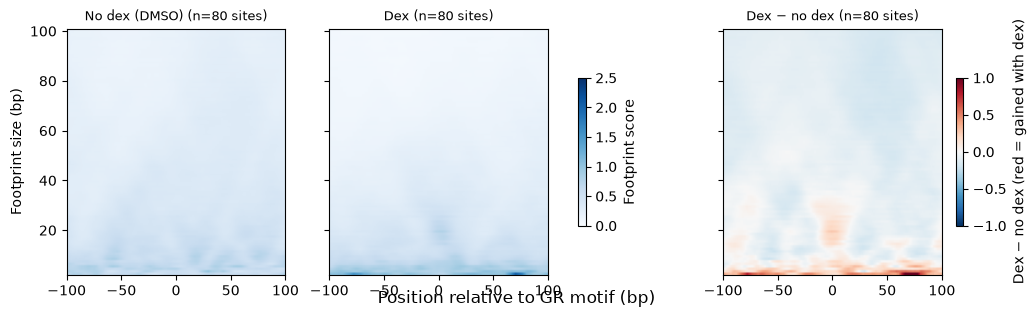

In [11]:
#aggregated gr footprint over inc. num sites
fp_path = os.path.join(printer.file_path, "GR_dex_sites.h5ad")
i_no, i_dex = list(groups2).index("no_dex"), list(groups2).index("dex")

set_sizes = [500, 1500, 3000]   
half_width = 100                
show_diff = True                
random_order = True             
seed = 0

n_sites = len(agg_regions)
order = np.random.default_rng(seed).permutation(n_sites) if random_order else np.arange(n_sites)
set_sizes = sorted({min(s, n_sites) for s in set_sizes})      

#one pass: keep a running sum 
avgs, running, n = {}, None, 0
with h5py.File(fp_path, "r", locking=False) as f:
    for i in order:
        fp = f["obsm"][agg_regions[i]][:]          # (2 groups, 99 scales, 1000 bp)
        if agg_strands[i] == "-":
            fp = fp[:, :, ::-1]                    # align all motifs in the same direction
        running = fp.astype(np.float64) if running is None else running + fp
        n += 1
        if n in set_sizes:
            avgs[n] = (running / n)[:, :, 500 - half_width : 500 + half_width]
        if n == set_sizes[-1]:
            break

#plotting
ncol = 3 if show_diff else 2
fig, axes = plt.subplots(len(set_sizes), ncol, figsize=(4 * ncol, 3.2 * len(set_sizes)),
                         sharex=True, sharey=True, squeeze=False)
ext = [-half_width, half_width, 2, 101]
for r, size in enumerate(set_sizes):
    a = avgs[size]
    for c, (idx, title) in enumerate([(i_no, "No dex (DMSO)"), (i_dex, "Dex")]):
        im = axes[r, c].imshow(a[idx], aspect="auto", origin="lower", cmap="Blues",
                               vmin=0, vmax=2.5, extent=ext)
        axes[r, c].set_title(f"{title} (n={size} sites)", fontsize=9)
    if show_diff:
        d = axes[r, 2].imshow(a[i_dex] - a[i_no], aspect="auto", origin="lower", cmap="RdBu_r",
                              vmin=-1, vmax=1, extent=ext)
        axes[r, 2].set_title(f"Dex − no dex (n={size} sites)", fontsize=9)
    axes[r, 0].set_ylabel("Footprint size (bp)")

fig.colorbar(im, ax=axes[:, :2], shrink=0.6, label="Footprint score")
if show_diff:
    fig.colorbar(d, ax=axes[:, 2], shrink=0.6, label="Dex − no dex (red = gained with dex)")
fig.supxlabel("Position relative to GR motif (bp)")

os.makedirs(os.path.join(wd, "plots"), exist_ok=True)
plt.savefig(os.path.join(wd, "plots", f"aggregate_GR_footprint_nsites_pm{half_width}.pdf"), bbox_inches="tight")
plt.show()

np.savez(os.path.join(wd, f"GR_aggregate_nsites_pm{half_width}.npz"),
         **{f"n{size}": avgs[size] for size in set_sizes}, groups=np.array(groups2))